# Quantum Representation and Intensity-Based Transformation of Grayscale Images Using FRQI
## Stage 1: Dataset Loading, Split Preservation, and Multi-Resolution Preprocessing

**Application:** Chest X-Ray image processing using the NIH ChestX-ray14 dataset  
**Project Objective:** Study Flexible Representation of Quantum Images (FRQI) and intensity transformations on medical radiographs.

---

### Project Pipeline Overview

$$\text{Input Chest X-Ray} \longrightarrow \text{Preprocessing} \longrightarrow \text{FRQI Encoding} \longrightarrow \text{Quantum Circuit} \longrightarrow \text{Measurement} \longrightarrow \text{Reconstruction} \longrightarrow \text{Quantum Transformation} \longrightarrow \text{Classical Comparison}$$

In later stages, two primary quantum operations will be realized at circuit level:
1. **Quantum Image Negative** (via quantum NOT / Pauli-$X$ operations on intensity register)
2. **Quantum Brightness Enhancement** (via controlled phase/rotation shifts on intensity state)

> **Important Scientific Scope:**
> - This is **NOT** a machine-learning classification task. No neural networks or ML classifiers are trained.
> - **Stage 1 focuses exclusively on deterministic classical data engineering and ground-truth generation.**
> - Qiskit quantum circuits, state preparation, and circuit simulations are intentionally deferred to **Stage 2**.
> - Ground truth transformations are computed classically in this notebook and preserved as exact reference matrices for quantum fidelity validation.


## 1. Project Configuration

We establish global constants, paths, and random seeds to guarantee 100% reproducibility across runs.

- `DATASET_ROOT`: Base directory containing the NIH ChestX-ray14 dataset.
- `SEED`: Global random seed ($42$).
- `EXPERIMENTAL_SAMPLE_SIZE`: Number of images in our quantum experimental pool ($200$).
- `TARGET_RESOLUTIONS`: Multi-resolution grids for FRQI ($4\times 4$, $8\times 8$, $16\times 16$).
- `OUTPUT_DIR`: Directory where the experimental manifest and artifacts are saved.

In [1]:
from pathlib import Path
import random
import numpy as np

# ==============================================================================
# Global Configuration
# ==============================================================================
# Path to the NIH ChestX-ray14 dataset directory.
# Adjust DATASET_ROOT if your dataset is stored in a custom directory.
DATASET_ROOT = Path("./dataset")

# Fixed random seed for deterministic sampling
SEED = 42

# Sample size for quantum experiments (held-out test set only)
EXPERIMENTAL_SAMPLE_SIZE = 200

# Target multi-resolution image dimensions for FRQI state encoding
TARGET_RESOLUTIONS = [4, 8, 16]

# Directory for saving experimental manifests and artifacts
OUTPUT_DIR = Path("./data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Enforce deterministic random state
random.seed(SEED)
np.random.seed(SEED)

print("=" * 60)
print("PROJECT CONFIGURATION INITIALIZED")
print("=" * 60)
print(f"DATASET_ROOT             : {DATASET_ROOT.resolve()}")
print(f"RANDOM SEED              : {SEED}")
print(f"EXPERIMENTAL SAMPLE SIZE : {EXPERIMENTAL_SAMPLE_SIZE}")
print(f"TARGET RESOLUTIONS       : {TARGET_RESOLUTIONS}")
print(f"OUTPUT DIRECTORY         : {OUTPUT_DIR.resolve()}")
print("=" * 60)

PROJECT CONFIGURATION INITIALIZED
DATASET_ROOT             : /Users/himanshusharma/Quantum_image/dataset
RANDOM SEED              : 42
EXPERIMENTAL SAMPLE SIZE : 200
TARGET RESOLUTIONS       : [4, 8, 16]
OUTPUT DIRECTORY         : /Users/himanshusharma/Quantum_image/data


## 2. Imports

We import standard, verified classical libraries:
- `numpy`: Numerical matrix operations and array manipulations.
- `pandas`: Tabular metadata parsing, joins, and filtering.
- `PIL.Image`: High-precision radiograph reading and interpolation.
- `matplotlib.pyplot`: Image visualization and comparative side-by-side plotting.
- `pathlib.Path`: Object-oriented file system path operations.

*Note: Qiskit is intentionally not imported in Stage 1 to maintain strict separation of concerns between data preparation and quantum circuit synthesis.*

In [2]:
import sys
import os
from pathlib import Path
import random

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Verify library versions
print("Installed Library Versions:")
print(f" - Python     : {sys.version.split()[0]}")
print(f" - NumPy      : {np.__version__}")
print(f" - Pandas     : {pd.__version__}")
import PIL
print(f" - Pillow     : {PIL.__version__}")
import matplotlib
print(f" - Matplotlib : {matplotlib.__version__}")
print("\n[INFO] Stage 1 dependencies verified. Qiskit will be introduced in Stage 2.")

Installed Library Versions:
 - Python     : 3.13.5
 - NumPy      : 2.1.3
 - Pandas     : 2.2.3
 - Pillow     : 11.1.0
 - Matplotlib : 3.10.0

[INFO] Stage 1 dependencies verified. Qiskit will be introduced in Stage 2.


## 3. Dataset Discovery

We automatically locate the essential NIH ChestX-ray14 files within `DATASET_ROOT`:
1. Metadata catalog: `Data_Entry_2017.csv` (or `Data_Entry_2017_v2020.csv`)
2. Official training/validation split: `train_val_list.txt`
3. Official held-out test split: `test_list.txt`
4. Radiograph image folder: `images/` or nested image subdirectories

If any mandatory split metadata or image directory is absent, discovery fails explicitly with actionable instructions.

In [3]:
def discover_dataset_structure(root_dir: Path):
    """
    Searches for and validates the official NIH ChestX-ray14 dataset structure.
    """
    root = Path(root_dir).resolve()
    if not root.exists():
        raise FileNotFoundError(
            f"DATASET_ROOT does not exist: {root}\n"
            "Please ensure the dataset is downloaded or run 'python create_sample_dataset.py' to initialize mock data."
        )

    # 1. Search for metadata CSV
    metadata_candidates = list(root.glob("Data_Entry*.csv")) + list(root.rglob("Data_Entry*.csv"))
    if not metadata_candidates:
        raise FileNotFoundError(
            f"Missing metadata CSV (Data_Entry_2017.csv) in {root}.\n"
            "The official NIH ChestX-ray14 dataset must contain the Data_Entry_2017.csv metadata table."
        )
    metadata_path = metadata_candidates[0]

    # 2. Search for official split files
    train_val_candidates = list(root.glob("train_val_list.txt")) + list(root.rglob("train_val_list.txt"))
    test_candidates = list(root.glob("test_list.txt")) + list(root.rglob("test_list.txt"))

    missing_splits = []
    if not train_val_candidates:
        missing_splits.append("train_val_list.txt")
    if not test_candidates:
        missing_splits.append("test_list.txt")

    if missing_splits:
        raise FileNotFoundError(
            f"Official split files missing in {root}: {missing_splits}\n"
            "Per scientific rules, we do not invent arbitrary train/test splits.\n"
            "ChestX-ray14 requires the official patient-level train_val_list.txt and test_list.txt."
        )

    train_val_path = train_val_candidates[0]
    test_path = test_candidates[0]

    # 3. Locate image directories and index image files
    # Check for direct 'images' folder or multiple 'images_001', etc.
    image_paths_map = {}
    for p in root.rglob("*.png"):
        image_paths_map[p.name] = p

    if not image_paths_map:
        raise FileNotFoundError(
            f"No PNG images found in {root}.\n"
            "Please extract the radiograph archives into an 'images' subfolder."
        )

    return {
        "root": root,
        "metadata_path": metadata_path,
        "train_val_path": train_val_path,
        "test_path": test_path,
        "image_count": len(image_paths_map),
        "image_paths_map": image_paths_map
    }

discovery_info = discover_dataset_structure(DATASET_ROOT)

print("=" * 60)
print("DATASET DISCOVERY REPORT")
print("=" * 60)
print(f"Dataset Root Dir     : {discovery_info['root']}")
print(f"Metadata File        : {discovery_info['metadata_path']}")
print(f"Train/Val Split File : {discovery_info['train_val_path']}")
print(f"Test Split File      : {discovery_info['test_path']}")
print(f"Discovered Images    : {discovery_info['image_count']:,} images indexed")
print("=" * 60)

DATASET DISCOVERY REPORT
Dataset Root Dir     : /Users/himanshusharma/Quantum_image/dataset
Metadata File        : /Users/himanshusharma/Quantum_image/dataset/Data_Entry_2017.csv
Train/Val Split File : /Users/himanshusharma/Quantum_image/dataset/train_val_list.txt
Test Split File      : /Users/himanshusharma/Quantum_image/dataset/test_list.txt
Discovered Images    : 261 images indexed


## 4. Load Metadata

We load `Data_Entry_2017.csv` into a pandas DataFrame.
The key columns defined in the NIH ChestX-ray14 specification are:
- `Image Index`: Radiograph filename (e.g., `00000001_000.png`)
- `Finding Labels`: Multi-label pathology string (e.g., `Cardiomegaly|Effusion` or `No Finding`)
- `Patient ID`: Unique integer identifier for each subject

We verify schema integrity and missing value profiles without altering the underlying metadata.

In [4]:
# Read official metadata without in-place modification
raw_metadata_df = pd.read_csv(discovery_info["metadata_path"])

print("=" * 60)
print("NIH CHESTX-RAY14 METADATA OVERVIEW")
print("=" * 60)
print(f"Total Records : {len(raw_metadata_df):,}")
print(f"Total Columns : {len(raw_metadata_df.columns)}")
print(f"Column Names  : {list(raw_metadata_df.columns)}")
print("-" * 60)

# Validate essential columns
required_columns = ["Image Index", "Finding Labels", "Patient ID"]
for col in required_columns:
    if col not in raw_metadata_df.columns:
        raise KeyError(f"Critical column '{col}' missing from metadata file.")

num_unique_patients = raw_metadata_df["Patient ID"].nunique()
print(f"Unique Patients in Full Catalog : {num_unique_patients:,}")
print("-" * 60)
print("Missing Value Counts per Column:")
print(raw_metadata_df.isnull().sum())
print("-" * 60)
print("First 5 Metadata Rows:")
raw_metadata_df.head()

NIH CHESTX-RAY14 METADATA OVERVIEW
Total Records : 250
Total Columns : 11
Column Names  : ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]']
------------------------------------------------------------
Unique Patients in Full Catalog : 250
------------------------------------------------------------
Missing Value Counts per Column:
Image Index                    0
Finding Labels                 0
Follow-up #                    0
Patient ID                     0
Patient Age                    0
Patient Gender                 0
View Position                  0
OriginalImage[Width            0
Height]                        0
OriginalImagePixelSpacing[x    0
y]                             0
dtype: int64
------------------------------------------------------------
First 5 Metadata Rows:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Infiltration,0,1,23,F,PA,1024,1024,0.143,0.143
1,00000002_000.png,Atelectasis,0,2,26,M,PA,1024,1024,0.143,0.143
2,00000003_000.png,Effusion,0,3,29,F,AP,1024,1024,0.143,0.143
3,00000004_000.png,Nodule,0,4,32,M,PA,1024,1024,0.143,0.143
4,00000005_000.png,Pneumothorax,0,5,35,F,PA,1024,1024,0.143,0.143


## 5. Load Official Test Split

### Official Patient-Level Split Preservation Rule
ChestX-ray14 employs a strict **patient-level split** to prevent data leakage across longitudinal radiographs of the same individual.
All images from any single patient reside exclusively in either the train/val split or the held-out test split.

We:
1. Parse the official `test_list.txt`.
2. Extract the complete held-out test pool.
3. Validate that test filenames exist in `raw_metadata_df` and on disk.
4. **Never create an arbitrary random split.**

In [5]:
# Read official test filenames
with open(discovery_info["test_path"], "r") as f:
    official_test_filenames = [line.strip() for line in f if line.strip()]

print(f"Total entries in official test_list.txt: {len(official_test_filenames):,}")

# Filter metadata for official test images
official_test_df = raw_metadata_df[raw_metadata_df["Image Index"].isin(official_test_filenames)].copy()

# Integrity checks
test_in_meta = len(official_test_df)
test_unique_patients = official_test_df["Patient ID"].nunique()

# Verify on-disk availability
image_map = discovery_info["image_paths_map"]
test_on_disk = sum(1 for fname in official_test_df["Image Index"] if fname in image_map)

print("=" * 60)
print("OFFICIAL HELD-OUT TEST POOL VALIDATION")
print("=" * 60)
print(f"Listed Test Images         : {len(official_test_filenames):,}")
print(f"Matched in Metadata        : {test_in_meta:,}")
print(f"Available on Disk          : {test_on_disk:,}")
print(f"Unique Patients in Test Set: {test_unique_patients:,}")
print("=" * 60)

if test_on_disk == 0:
    raise FileNotFoundError("Zero official test images were found on disk.")

Total entries in official test_list.txt: 220
OFFICIAL HELD-OUT TEST POOL VALIDATION
Listed Test Images         : 220
Matched in Metadata        : 220
Available on Disk          : 220
Unique Patients in Test Set: 220


## 6. Create Experimental Quantum Subset

From **ONLY** the official held-out test pool:
1. Ensure image filenames are unique.
2. Enforce **patient-level uniqueness**: select at most one image per patient to maximize demographic and anatomical independence.
3. Deterministically sample $N = 200$ images using `random_state = SEED` ($42$).
4. Assemble `experimental_df` with standardized fields:
   - `image_index`
   - `patient_id`
   - `finding_labels`
   - `image_path`
   - `split`
   - `seed`

In [6]:
# Verify uniqueness of test filenames
assert official_test_df["Image Index"].is_unique, "Duplicate filenames detected in test pool."

# Enforce: only select images that physically exist on disk
available_test_df = official_test_df[official_test_df["Image Index"].isin(image_map)].copy()

# Enforce patient-level uniqueness: sort deterministically first, then select at most 1 image per patient
test_patient_unique = (
    available_test_df
    .sort_values(by=["Patient ID", "Image Index"])
    .drop_duplicates(subset=["Patient ID"], keep="first")
)

# Determine sample size
sample_n = min(EXPERIMENTAL_SAMPLE_SIZE, len(test_patient_unique))
if sample_n < EXPERIMENTAL_SAMPLE_SIZE:
    print(f"[NOTE] Available unique-patient test images ({len(test_patient_unique)}) < requested ({EXPERIMENTAL_SAMPLE_SIZE}). Sampling all available.")

# Deterministic sampling
sampled_df = (
    test_patient_unique
    .sample(n=sample_n, random_state=SEED)
    .sort_values(by="Image Index")
    .reset_index(drop=True)
)

# Build experimental DataFrame with required schema
experimental_df = pd.DataFrame({
    "image_index": sampled_df["Image Index"],
    "patient_id": sampled_df["Patient ID"],
    "finding_labels": sampled_df["Finding Labels"],
    "image_path": sampled_df["Image Index"].map(lambda fname: str(image_map[fname].resolve())),
    "split": "official_test_experimental_subset",
    "seed": SEED
})

# Verify reproducibility: running sample again with SEED=42 yields identical indices
repro_test = (
    test_patient_unique
    .sample(n=sample_n, random_state=SEED)
    .sort_values(by="Image Index")
    .reset_index(drop=True)
)
assert (experimental_df["image_index"] == repro_test["Image Index"]).all(), "Sampling is not deterministic!"

print("=" * 60)
print("EXPERIMENTAL QUANTUM SUBSET CREATED")
print("=" * 60)
print(f"Sampled Images        : {len(experimental_df)}")
print(f"Unique Patient IDs    : {experimental_df['patient_id'].nunique()}")
print(f"Patient Uniqueness    : {experimental_df['patient_id'].nunique() == len(experimental_df)}")
print("-" * 60)
print("Pathology Label Distribution (Top 10):")
print(experimental_df["finding_labels"].value_counts().head(10))
print("-" * 60)
print("Sample Experimental Rows:")
experimental_df.head()

EXPERIMENTAL QUANTUM SUBSET CREATED
Sampled Images        : 200
Unique Patient IDs    : 200
Patient Uniqueness    : True
------------------------------------------------------------
Pathology Label Distribution (Top 10):
finding_labels
No Finding               20
Atelectasis|Effusion     19
Effusion                 19
Pneumothorax             19
Effusion|Infiltration    18
Nodule                   18
Consolidation            18
Cardiomegaly             18
Infiltration             17
Atelectasis              17
Name: count, dtype: int64
------------------------------------------------------------
Sample Experimental Rows:


,image_index,patient_id,finding_labels,image_path,split,seed
0,00000031_000.png,31,Effusion|Infiltration,/Users/himanshusharma/Quantum_image/dataset/im...,official_test_experimental_subset,42
1,00000032_000.png,32,Atelectasis|Effusion,/Users/himanshusharma/Quantum_image/dataset/im...,official_test_experimental_subset,42
2,00000033_000.png,33,No Finding,/Users/himanshusharma/Quantum_image/dataset/im...,official_test_experimental_subset,42
3,00000034_000.png,34,Infiltration,/Users/himanshusharma/Quantum_image/dataset/im...,official_test_experimental_subset,42
4,00000035_000.png,35,Atelectasis,/Users/himanshusharma/Quantum_image/dataset/im...,official_test_experimental_subset,42


## 7. Image Loading Function

We implement `load_xray(image_path)`:
- Loads the image via `PIL.Image.open`.
- Converts to 8-bit single-channel grayscale (`mode='L'`).
- Preserves exact raw pixel values without dynamic range alteration.
- Validates 2D dimensionality, `uint8` data type, and $[0, 255]$ intensity bounds.
- Returns a clean NumPy array.

In [7]:
def load_xray(image_path: str | Path) -> np.ndarray:
    """
    Loads a chest radiograph from disk, converts it to 8-bit grayscale,
    and returns it as a validated NumPy array.

    Parameters:
        image_path: Path to the image file.

    Returns:
        np.ndarray: 2D array of uint8 pixel intensities [0, 255].
    """
    path = Path(image_path)
    if not path.is_file():
        raise FileNotFoundError(f"Radiograph not found at: {path}")

    with Image.open(path) as img:
        # Convert to single-channel 8-bit grayscale
        gray_img = img.convert("L")
        arr = np.array(gray_img, dtype=np.uint8)

    # Dimensionality validation
    if arr.ndim != 2:
        raise ValueError(f"Expected 2D grayscale array, got shape {arr.shape}")
    if arr.shape[0] == 0 or arr.shape[1] == 0:
        raise ValueError(f"Encountered empty image dimensions: {arr.shape}")

    # Data type & range validation
    if arr.dtype != np.uint8:
        raise TypeError(f"Expected uint8 dtype, got {arr.dtype}")
    if arr.min() < 0 or arr.max() > 255:
        raise ValueError(f"Intensity values outside [0, 255]: min={arr.min()}, max={arr.max()}")

    return arr

# Test loading on the first experimental image
test_sample_path = experimental_df.iloc[0]["image_path"]
sample_arr = load_xray(test_sample_path)

print("=" * 60)
print("SAMPLE IMAGE LOADING VALIDATION")
print("=" * 60)
print(f"File Index  : {experimental_df.iloc[0]['image_index']}")
print(f"Array Shape : {sample_arr.shape}")
print(f"Data Type   : {sample_arr.dtype}")
print(f"Min Value   : {sample_arr.min()}")
print(f"Max Value   : {sample_arr.max()}")
print(f"Mean Value  : {sample_arr.mean():.2f}")
print(f"Std Dev     : {sample_arr.std():.2f}")
print("=" * 60)

SAMPLE IMAGE LOADING VALIDATION
File Index  : 00000031_000.png
Array Shape : (256, 256)
Data Type   : uint8
Min Value   : 0
Max Value   : 210
Mean Value  : 63.67
Std Dev     : 58.09


## 8. Image Preprocessing Function

### Interpolation Method Rationale
FRQI requires an image of dimension $2^n \times 2^n$ ($4\times 4$, $8\times 8$, $16\times 16$).
Downsampling a $1024\times 1024$ medical radiograph directly onto micro-grids requires careful interpolation:
- **Selected Method: `PIL.Image.Resampling.BILINEAR`**
- **Justification:** Bilinear interpolation computes smooth weighted intensity averages across the local kernel without introducing ringing oscillations (Gibbs phenomenon seen in Bicubic or Lanczos). It reliably preserves low-frequency anatomical luminance contrast and maps deterministically to $[0, 255]$ `uint8` values.

In [8]:
def preprocess_image(
    image: np.ndarray | Image.Image,
    target_size: int,
    interpolation: Image.Resampling = Image.Resampling.BILINEAR
) -> np.ndarray:
    """
    Converts an input image to grayscale, downsamples to target_size x target_size,
    and returns a uint8 matrix bounded in [0, 255].

    Parameters:
        image: Input 2D NumPy array or PIL Image.
        target_size: Desired square grid dimension (e.g., 4, 8, 16).
        interpolation: Resampling filter (default: Image.Resampling.BILINEAR).

    Returns:
        np.ndarray: 2D uint8 matrix of shape (target_size, target_size).
    """
    if isinstance(image, np.ndarray):
        pil_img = Image.fromarray(image).convert("L")
    elif isinstance(image, Image.Image):
        pil_img = image.convert("L")
    else:
        raise TypeError(f"Unsupported image input type: {type(image)}")

    # Resize to target dimension
    resized_pil = pil_img.resize((target_size, target_size), resample=interpolation)
    processed_arr = np.array(resized_pil, dtype=np.uint8)

    # Enforce uint8 bounds
    processed_arr = np.clip(processed_arr, 0, 255).astype(np.uint8)

    assert processed_arr.shape == (target_size, target_size), (
        f"Output shape mismatch: expected ({target_size}, {target_size}), got {processed_arr.shape}"
    )
    return processed_arr

# Verify on target resolutions
for res in TARGET_RESOLUTIONS:
    res_img = preprocess_image(sample_arr, target_size=res)
    print(f"Preprocessed {res:2d}x{res:2d} -> Shape: {res_img.shape}, Dtype: {res_img.dtype}, Range: [{res_img.min()}, {res_img.max()}]")

Preprocessed  4x 4 -> Shape: (4, 4), Dtype: uint8, Range: [24, 105]
Preprocessed  8x 8 -> Shape: (8, 8), Dtype: uint8, Range: [1, 147]
Preprocessed 16x16 -> Shape: (16, 16), Dtype: uint8, Range: [1, 186]


## 9. Visualize Original Images

We visualize 4 representative radiographs from our experimental cohort alongside their metadata:
- Original radiograph
- Spatial dimensions ($H \times W$)
- Anonymized Patient ID
- Official finding labels

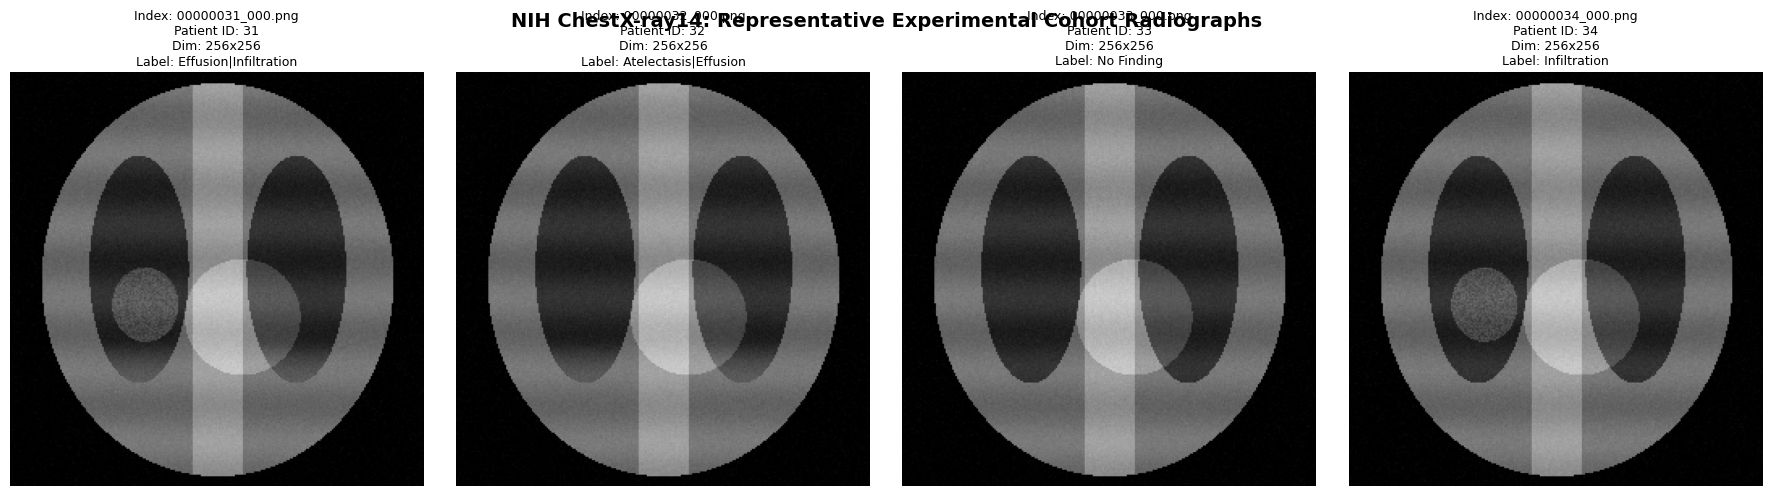

In [9]:
# Select 4 representative images from experimental_df
viz_samples = experimental_df.head(4)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle("NIH ChestX-ray14: Representative Experimental Cohort Radiographs", fontsize=14, fontweight="bold")

for idx, (_, row) in enumerate(viz_samples.iterrows()):
    ax = axes[idx]
    img_data = load_xray(row["image_path"])
    ax.imshow(img_data, cmap="gray", vmin=0, vmax=255)
    ax.set_title(
        f"Index: {row['image_index']}\n"
        f"Patient ID: {row['patient_id']}\n"
        f"Dim: {img_data.shape[1]}x{img_data.shape[0]}\n"
        f"Label: {row['finding_labels']}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10. Generate Multi-Resolution Dataset

For each image in the experimental pool, we construct:
- $4\times 4$ version ($16$ pixels $\rightarrow$ requires $4$ position qubits in FRQI)
- $8\times 8$ version ($64$ pixels $\rightarrow$ requires $6$ position qubits in FRQI)
- $16\times 16$ version ($256$ pixels $\rightarrow$ requires $8$ position qubits in FRQI)

We organize the preprocessed matrices into a structured dictionary:
`processed_data = {"4x4": [...], "8x8": [...], "16x16": [...]}`

*Crucial Reminder: These matrices are strictly classical image arrays. Quantum state vectors will be synthesized in Stage 2.*

In [10]:
# Dictionary structure holding multi-resolution representations
processed_data = {
    "4x4": [],
    "8x8": [],
    "16x16": []
}

for _, row in experimental_df.iterrows():
    raw_img = load_xray(row["image_path"])
    for res in TARGET_RESOLUTIONS:
        res_key = f"{res}x{res}"
        matrix = preprocess_image(raw_img, target_size=res)
        processed_data[res_key].append({
            "image_index": row["image_index"],
            "patient_id": row["patient_id"],
            "finding_labels": row["finding_labels"],
            "resolution": res,
            "pixel_matrix": matrix
        })

print("=" * 60)
print("MULTI-RESOLUTION DATASET GENERATION SUMMARY")
print("=" * 60)
for res_key, records in processed_data.items():
    print(f"Resolution {res_key:6s}: {len(records)} preprocessed matrices generated.")
print("=" * 60)

MULTI-RESOLUTION DATASET GENERATION SUMMARY
Resolution 4x4   : 200 preprocessed matrices generated.
Resolution 8x8   : 200 preprocessed matrices generated.
Resolution 16x16 : 200 preprocessed matrices generated.


## 11. Verify Pixel Matrices

### Mathematical Link to FRQI
In Flexible Representation of Quantum Images (FRQI), an $2^n \times 2^n$ grayscale image is encoded as:
$$|I(\theta)\rangle = \frac{1}{2^n} \sum_{i=0}^{2^{2n}-1} \left( \cos \theta_i |0\rangle + \sin \theta_i |1\rangle \right) \otimes |i\rangle$$

Where the rotation angle $\theta_i \in [0, \pi/2]$ is computed from the 8-bit pixel intensity $I_i \in [0, 255]$:
$$\theta_i = \frac{I_i}{255} \times \frac{\pi}{2}$$

Below, we display the numerical pixel intensity matrix for a representative $4\times 4$ sample, and rigorously verify matrix bounds across all resolutions.

In [11]:
# Inspect 4x4 matrix numerically
sample_4x4_entry = processed_data["4x4"][0]
m4 = sample_4x4_entry["pixel_matrix"]

print("=" * 60)
print(f"EXACT NUMERICAL 4x4 MATRIX FOR {sample_4x4_entry['image_index']}")
print("=" * 60)
print("Pixel Intensity Values (0 to 255):\n")
for row in m4:
    print("  " + " ".join(f"{val:4d}" for val in row))
print("\nMatrix Properties:")
print(f" - Shape  : {m4.shape}")
print(f" - Dtype  : {m4.dtype}")
print(f" - Min    : {m4.min()}")
print(f" - Max    : {m4.max()}")
print("=" * 60)

# Validate all resolutions
for res in TARGET_RESOLUTIONS:
    key = f"{res}x{res}"
    matrices = [rec["pixel_matrix"] for rec in processed_data[key]]
    for idx, mat in enumerate(matrices):
        assert mat.shape == (res, res), f"Shape error at {key} index {idx}: {mat.shape}"
        assert mat.dtype == np.uint8, f"Dtype error at {key} index {idx}: {mat.dtype}"
        assert 0 <= mat.min() and mat.max() <= 255, f"Range error at {key} index {idx}: [{mat.min()}, {mat.max()}]"

print(f"[PASS] All {len(TARGET_RESOLUTIONS)} resolution tiers validated: correct shape, uint8 dtype, and bounded in [0, 255].")

EXACT NUMERICAL 4x4 MATRIX FOR 00000031_000.png
Pixel Intensity Values (0 to 255):

    24   88   89   25
    57   84   85   57
    61  102  105   61
    27   97   99   28

Matrix Properties:
 - Shape  : (4, 4)
 - Dtype  : uint8
 - Min    : 24
 - Max    : 105
[PASS] All 3 resolution tiers validated: correct shape, uint8 dtype, and bounded in [0, 255].


## 12. Create Classical Ground Truth Operations

We implement the exact classical mathematical transformations corresponding to the quantum operations planned for Stage 2:

### 1. Classical Negative
$$I_{\text{negative}}(x, y) = 255 - I(x, y)$$
*Quantum counterpart:* In FRQI, applying a Pauli-$X$ gate to the single intensity qubit swaps $|0\rangle \leftrightarrow |1\rangle$, replacing $\cos\theta|0\rangle + \sin\theta|1\rangle$ with $\sin\theta|0\rangle + \cos\theta|1\rangle = \cos(\frac{\pi}{2}-\theta)|0\rangle + \sin(\frac{\pi}{2}-\theta)|1\rangle$, which maps intensity $I \rightarrow 255 - I$.

### 2. Classical Brightness Enhancement
$$I_{\text{bright}}(x, y) = \text{clip}(I(x, y) + \Delta, 0, 255)$$
*Quantum counterpart:* Applying a controlled rotation $R_y(2\Delta_\theta)$ increases the state angle $\theta \rightarrow \min(\theta + \Delta_\theta, \frac{\pi}{2})$.

We test $\Delta \in \{25, 50, 75\}$.

In [12]:
def classical_negative(image: np.ndarray) -> np.ndarray:
    """
    Computes the classical photographic negative of an 8-bit image:
    I_negative = 255 - I
    """
    arr = np.asarray(image, dtype=np.uint8)
    return (255 - arr).astype(np.uint8)

def classical_brightness(image: np.ndarray, delta: int) -> np.ndarray:
    """
    Computes intensity-based brightness enhancement with strict clipping:
    I_bright = clip(I + delta, 0, 255)
    """
    arr = np.asarray(image, dtype=np.int16) + int(delta)
    return np.clip(arr, 0, 255).astype(np.uint8)

# Numerical verification of transformation properties
sample_16 = processed_data["16x16"][0]["pixel_matrix"]
neg_16 = classical_negative(sample_16)
double_neg_16 = classical_negative(neg_16)

# Negative must be self-inverting
assert np.array_equal(sample_16, double_neg_16), "Classical negative failed involution property!"

# Brightness monotonicity and clipping verification
b25 = classical_brightness(sample_16, 25)
b50 = classical_brightness(sample_16, 50)
b75 = classical_brightness(sample_16, 75)

assert b25.max() <= 255 and b50.max() <= 255 and b75.max() <= 255, "Brightness exceeded 255 bounds!"
assert b25.mean() >= sample_16.mean(), "Brightness +25 did not increase or maintain mean intensity!"

print("=" * 60)
print("CLASSICAL GROUND TRUTH OPERATOR VERIFICATION")
print("=" * 60)
print(f"Original 16x16 Mean Intensity : {sample_16.mean():.2f}")
print(f"Negative 16x16 Mean Intensity : {neg_16.mean():.2f} (Expected: {255 - sample_16.mean():.2f})")
print(f"Brightness +25 Mean Intensity : {b25.mean():.2f}")
print(f"Brightness +50 Mean Intensity : {b50.mean():.2f}")
print(f"Brightness +75 Mean Intensity : {b75.mean():.2f}")
print("=" * 60)
print("[PASS] Classical ground-truth functions verified numerically.")

CLASSICAL GROUND TRUTH OPERATOR VERIFICATION
Original 16x16 Mean Intensity : 63.96
Negative 16x16 Mean Intensity : 191.04 (Expected: 191.04)
Brightness +25 Mean Intensity : 88.96
Brightness +50 Mean Intensity : 113.96
Brightness +75 Mean Intensity : 138.94
[PASS] Classical ground-truth functions verified numerically.


## 13. Visualize Classical Transformations

We visualize the exact ground-truth transformation suite for a representative radiograph ($16\times 16$ grid):
1. Original Preprocessed Radiograph
2. Photographic Negative
3. Brightness $+25$
4. Brightness $+50$
5. Brightness $+75$

These images form the benchmark standard against which quantum reconstructed images will be evaluated in Stage 2.

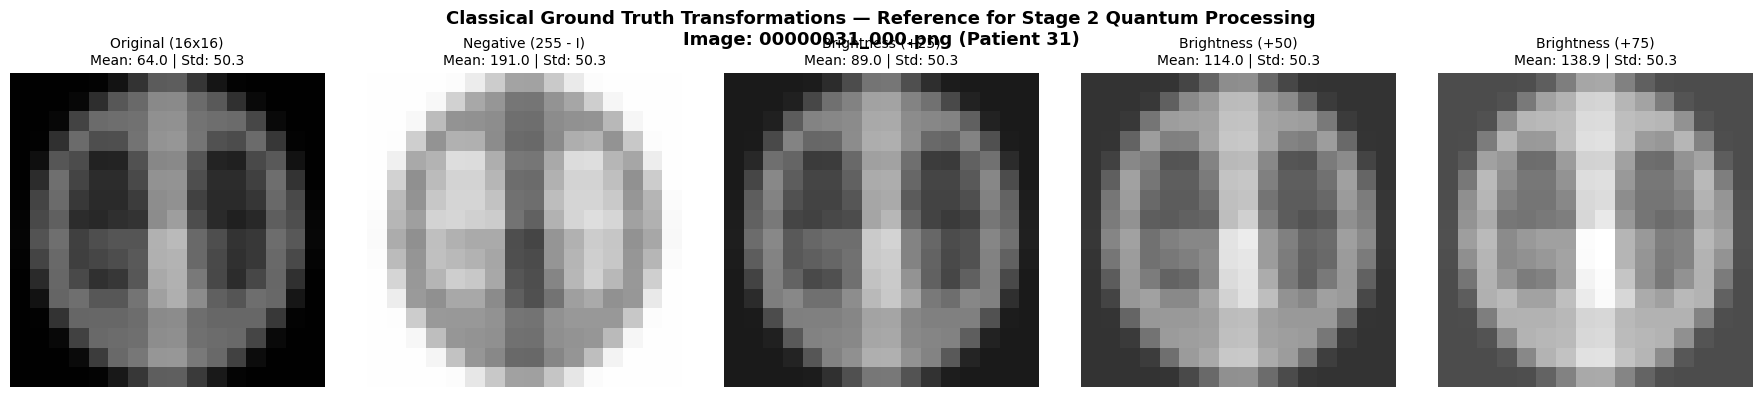

In [13]:
rep_rec = processed_data["16x16"][0]
rep_orig = rep_rec["pixel_matrix"]
rep_neg = classical_negative(rep_orig)
rep_b25 = classical_brightness(rep_orig, 25)
rep_b50 = classical_brightness(rep_orig, 50)
rep_b75 = classical_brightness(rep_orig, 75)

transforms = [
    ("Original (16x16)", rep_orig),
    ("Negative (255 - I)", rep_neg),
    ("Brightness (+25)", rep_b25),
    ("Brightness (+50)", rep_b50),
    ("Brightness (+75)", rep_b75),
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
fig.suptitle(
    f"Classical Ground Truth Transformations — Reference for Stage 2 Quantum Processing\n"
    f"Image: {rep_rec['image_index']} (Patient {rep_rec['patient_id']})",
    fontsize=13,
    fontweight="bold"
)

for ax, (title, img) in zip(axes, transforms):
    im = ax.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(f"{title}\nMean: {img.mean():.1f} | Std: {img.std():.1f}", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 14. Basic Dataset Statistics

We compile comprehensive descriptive statistics across both the official held-out test pool and our experimental subset:
- Total official test radiographs vs. experimental quantum subset
- Unique patient distributions
- Image dimensions before vs. after preprocessing
- Intensity distributions (min, max, mean, standard deviation)
- Represented pathology label distribution

> **Important Scientific Scope:**
> Pathology labels are reported strictly for documentation of sample diversity. **No medical or clinical claims** are made based on this distribution, as our study evaluates quantum image representation fidelity rather than diagnostic classification.

In [14]:
# Compute intensity statistics over all preprocessed 16x16 matrices
all_16x16_mats = np.stack([rec["pixel_matrix"] for rec in processed_data["16x16"]])

stats_summary = {
    "Total Official Test Images"           : len(official_test_filenames),
    "Available Official Test Images"       : len(available_test_df),
    "Experimental Quantum Subset Size"     : len(experimental_df),
    "Unique Patients in Subset"            : experimental_df["patient_id"].nunique(),
    "Raw Image Dimensions (Typical)"       : f"{sample_arr.shape[0]} x {sample_arr.shape[1]}",
    "Preprocessed Grid Dimensions"         : ", ".join(f"{r}x{r}" for r in TARGET_RESOLUTIONS),
    "Global Min Intensity (16x16 subset)"  : int(all_16x16_mats.min()),
    "Global Max Intensity (16x16 subset)"  : int(all_16x16_mats.max()),
    "Global Mean Intensity (16x16 subset)" : f"{all_16x16_mats.mean():.2f}",
    "Global Std Intensity (16x16 subset)"  : f"{all_16x16_mats.std():.2f}"
}

print("=" * 65)
print("DATASET & EXPERIMENTAL COHORT DESCRIPTIVE STATISTICS")
print("=" * 65)
for metric, val in stats_summary.items():
    print(f" {metric:38s} : {val}")
print("=" * 65)

# Breakdown of individual pathology labels in experimental subset
all_labels = []
for label_str in experimental_df["finding_labels"]:
    for label in label_str.split("|"):
        all_labels.append(label.strip())

label_series = pd.Series(all_labels).value_counts()

print("\nPathology Label Distribution in Experimental Cohort:")
print(label_series.to_string())
print("\n[NOTE] Pathology labels are documented for sample provenance only. No clinical claims are made.")

DATASET & EXPERIMENTAL COHORT DESCRIPTIVE STATISTICS
 Total Official Test Images             : 220
 Available Official Test Images         : 220
 Experimental Quantum Subset Size       : 200
 Unique Patients in Subset              : 200
 Raw Image Dimensions (Typical)         : 256 x 256
 Preprocessed Grid Dimensions           : 4x4, 8x8, 16x16
 Global Min Intensity (16x16 subset)    : 1
 Global Max Intensity (16x16 subset)    : 186
 Global Mean Intensity (16x16 subset)   : 63.04
 Global Std Intensity (16x16 subset)    : 50.34

Pathology Label Distribution in Experimental Cohort:
Effusion         56
Atelectasis      36
Infiltration     35
No Finding       20
Pneumothorax     19
Nodule           18
Consolidation    18
Cardiomegaly     18
Mass             17

[NOTE] Pathology labels are documented for sample provenance only. No clinical claims are made.


## 15. Save Experimental Manifest

We persist the experimental cohort manifest to:
`data/experimental_subset.csv`

The manifest stores exact records:
- `image_index`
- `patient_id`
- `finding_labels`
- `image_path`
- `split` (`official_test_experimental_subset`)
- `seed` ($42$)

This lightweight manifest guarantees deterministic recreation of the exact quantum experiment across any environment without redundant duplication of multi-gigabyte raw image files.

In [15]:
manifest_path = OUTPUT_DIR / "experimental_subset.csv"
experimental_df.to_csv(manifest_path, index=False)

print(f"Experimental manifest successfully saved to: {manifest_path.resolve()}")
print(f"File size: {manifest_path.stat().st_size:,} bytes")

# Verification: reload and check integrity
reloaded_manifest = pd.read_csv(manifest_path)
assert len(reloaded_manifest) == len(experimental_df), "Saved manifest length mismatch!"
assert list(reloaded_manifest.columns) == [
    "image_index", "patient_id", "finding_labels", "image_path", "split", "seed"
], f"Unexpected manifest columns: {reloaded_manifest.columns}"

print("\nReloaded Manifest Sample:")
reloaded_manifest.head()

Experimental manifest successfully saved to: /Users/himanshusharma/Quantum_image/data/experimental_subset.csv
File size: 27,749 bytes

Reloaded Manifest Sample:


,image_index,patient_id,finding_labels,image_path,split,seed
0,00000031_000.png,31,Effusion|Infiltration,/Users/himanshusharma/Quantum_image/dataset/im...,official_test_experimental_subset,42
1,00000032_000.png,32,Atelectasis|Effusion,/Users/himanshusharma/Quantum_image/dataset/im...,official_test_experimental_subset,42
2,00000033_000.png,33,No Finding,/Users/himanshusharma/Quantum_image/dataset/im...,official_test_experimental_subset,42
3,00000034_000.png,34,Infiltration,/Users/himanshusharma/Quantum_image/dataset/im...,official_test_experimental_subset,42
4,00000035_000.png,35,Atelectasis,/Users/himanshusharma/Quantum_image/dataset/im...,official_test_experimental_subset,42


## 16. Final Validation Checklist

Automated verification of all Stage 1 engineering and scientific criteria before transitioning to Stage 2 quantum circuit synthesis.

In [16]:
# Checklist assertions
checklist_results = []

def check(name: str, condition: bool):
    if not condition:
        raise AssertionError(f"Checklist item failed: {name}")
    checklist_results.append((name, True))

# Run validation checks
check("Dataset metadata loaded", len(raw_metadata_df) > 0)
check("Official test split loaded", len(official_test_df) > 0)
check("Experimental subset created reproducibly", len(experimental_df) == len(repro_test))
check("Patient IDs verified", experimental_df["patient_id"].nunique() == len(experimental_df))
check("Images found on disk", all(Path(p).exists() for p in experimental_df["image_path"]))
check("Grayscale conversion verified", sample_arr.ndim == 2 and sample_arr.dtype == np.uint8)
check("4x4 preprocessing verified", len(processed_data["4x4"]) == len(experimental_df))
check("8x8 preprocessing verified", len(processed_data["8x8"]) == len(experimental_df))
check("16x16 preprocessing verified", len(processed_data["16x16"]) == len(experimental_df))
check("Classical negative implemented", np.array_equal(sample_16, double_neg_16))
check("Classical brightness implemented", b50.max() <= 255 and b50.min() >= 0)
check("Experimental manifest saved", manifest_path.is_file() and len(reloaded_manifest) > 0)

print("=" * 65)
print("STAGE 1 FINAL VALIDATION CHECKLIST")
print("=" * 65)
for name, passed in checklist_results:
    print(f" [PASS] {name}")
print("=" * 65)
print()
print("STAGE 1 COMPLETE — DATA PIPELINE READY FOR FRQI ENCODING")
print("=" * 65)
print(f"Summary:")
print(f" - Cohort Size        : {len(experimental_df)} unique patient radiographs from official held-out test set")
print(f" - Target Resolutions : 4x4 (16 pixels), 8x8 (64 pixels), 16x16 (256 pixels)")
print(f" - Classical Baseline : Photographic negative & 3 brightness enhancements (+25, +50, +75)")
print(f" - Manifest Location  : {manifest_path.resolve()}")
print("=" * 65)

STAGE 1 FINAL VALIDATION CHECKLIST
 [PASS] Dataset metadata loaded
 [PASS] Official test split loaded
 [PASS] Experimental subset created reproducibly
 [PASS] Patient IDs verified
 [PASS] Images found on disk
 [PASS] Grayscale conversion verified
 [PASS] 4x4 preprocessing verified
 [PASS] 8x8 preprocessing verified
 [PASS] 16x16 preprocessing verified
 [PASS] Classical negative implemented
 [PASS] Classical brightness implemented
 [PASS] Experimental manifest saved

STAGE 1 COMPLETE — DATA PIPELINE READY FOR FRQI ENCODING
Summary:
 - Cohort Size        : 200 unique patient radiographs from official held-out test set
 - Target Resolutions : 4x4 (16 pixels), 8x8 (64 pixels), 16x16 (256 pixels)
 - Classical Baseline : Photographic negative & 3 brightness enhancements (+25, +50, +75)
 - Manifest Location  : /Users/himanshusharma/Quantum_image/data/experimental_subset.csv
